# 06. 추가 실험: 성별 위치 클리핑
각 직업의 lam을 [center − width, center + width]로 잘라서 생성했을 때 남성 비율이 어떻게 되는지,
05의 lam 곡선으로 미리 한 예측과 비교한다.

이 실험은 05 결과(lam_at_50pct가 모두 양수)를 보고 추가한 것이다. 생성: `scripts/generate_clamp.py --center 0.3 --width 0.1`

### 생성 전 예측 (2026-10-28 02:00 기록, 05 lam 곡선의 0과 +0.5 사이 직선 보간)
| 직업 | 원래 lam → 자른 뒤 | 원본 남성 비율 | 예측 |
|---|---|---|---|
| CEO | +0.67 → +0.40 | 0.98 | 0.79 |
| pilot | +0.54 → +0.40 | 0.92 | 0.76 |
| cashier | 0.00 → +0.20 | 0.24 | 0.47 |
| teacher | +0.01 → +0.20 | 0.12 | 0.38 |
| nanny | −0.40 → +0.20 | 0.05 | 0.27 |
| nurse | −0.43 → +0.20 | 0.00 | 0.26 |

## 1. 불러오기

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.utils import *
from src.prompts import *
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

IMG = "../outputs/images_clamp/"
FIG = "../figures/"
TAG = "c+0.30_w0.10"
JOB_ORDER = [j for js in GEN_JOBS.values() for j in js]
LAM_TAGS = [f"lam{l:+.1f}" for l in LAMS]

CLIP_PATH = next(p for p in ["../models/clip-l14", "../models/clipl14"] if Path(p).exists())
clip = CLIPModel.from_pretrained(CLIP_PATH, torch_dtype=torch.float16).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(CLIP_PATH)

PRED = pd.Series({"CEO": 0.79, "pilot": 0.76, "cashier": 0.47, "teacher": 0.38,
                  "nanny": 0.27, "nurse": 0.26})          # 생성 전 예측 (위 표)

W1028 02:14:54.279000 10844 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

## 2. 판정 (05와 같은 방식)
결과는 `data/judgments_clamp.csv`에 저장하고, 다음부터는 불러온다.

In [2]:
REDO = False
JPATH = Path("../data/judgments_clamp.csv")
GENDER_TEXTS = ["a photo of a man", "a photo of a woman", "a photo with no person"]
LABELS = np.array(["man", "woman", "none"])

@torch.no_grad()
def text_feats(texts):
    t = proc(text=texts, return_tensors="pt", padding=True).to(DEVICE)
    f = clip.text_projection(clip.text_model(**t).pooler_output)
    return f / f.norm(dim=-1, keepdim=True)

@torch.no_grad()
def image_feats(px):
    v = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
    return v / v.norm(dim=-1, keepdim=True)

meta = pd.read_csv("../data/clamp_meta.csv").drop_duplicates("file")
meta = meta[meta.tag == TAG].reset_index(drop=True)
meta["black"] = [np.asarray(Image.open(IMG + f)).max() == 0 for f in meta.file]
print(f"전체 {len(meta)}장 / 검은 이미지 {meta.black.sum()}장")
meta = meta[~meta.black].reset_index(drop=True)

if JPATH.exists() and not REDO:
    C = pd.read_csv(JPATH)
else:
    g_feat = text_feats(GENDER_TEXTS)
    j_feat = {j: text_feats([fill(GEN_TEMPLATE, j)])[0] for j in meta.job.unique()}
    preds, p_man, p_woman, scores = [], [], [], []
    for i in range(0, len(meta), 32):
        b = meta.iloc[i:i + 32]
        imgs = [Image.open(IMG + f).convert("RGB") for f in b.file]
        px = proc(images=imgs, return_tensors="pt")["pixel_values"].to(DEVICE, torch.float16)
        v = image_feats(px)
        pr = (100 * v @ g_feat.T).softmax(-1).float().cpu().numpy()
        preds += list(LABELS[pr.argmax(1)]); p_man += list(pr[:, 0]); p_woman += list(pr[:, 1])
        scores += [float(100 * (vv @ j_feat[j])) for vv, j in zip(v, b.job)]
    C = meta.assign(pred=preds, p_man=p_man, p_woman=p_woman, clip_score=scores)
    C.to_csv(JPATH, index=False)
print(C.pred.value_counts().to_string())

전체 300장 / 검은 이미지 0장
pred
woman    141
man      127
none      32


## 3. 예측 대 실제
원본 남성 비율은 05의 `judgments.csv`에서 가져온다.

In [3]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    mid = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return mid - half, mid + half

def male_rate(df):
    df = df[df.pred != "none"]
    g = df.groupby("job").agg(k=("pred", lambda x: (x == "man").sum()), n=("pred", "size"))
    g["rate"] = g.k / g.n
    g["lo"], g["hi"] = wilson(g.k, g.n)
    return g.loc[JOB_ORDER]

J = pd.read_csv("../data/judgments.csv")
orig = male_rate(J[J.cond == "original"])
clamp = male_rate(C)
target = C.groupby("job").target_lam.first().loc[JOB_ORDER]

res = pd.DataFrame({"target_lam": target, "original": orig.rate, "predicted": PRED.loc[JOB_ORDER],
                    "actual": clamp.rate, "ci_lo": clamp.lo, "ci_hi": clamp.hi})
res["error"] = res.actual - res.predicted
print(res.round(2).to_string())
print(f"\n남성 비율 범위  원본: {orig.rate.min():.2f} ~ {orig.rate.max():.2f}"
      f"  →  클리핑: {clamp.rate.min():.2f} ~ {clamp.rate.max():.2f}")
print(f"50%에서의 평균 거리  원본: {(orig.rate - 0.5).abs().mean():.2f}"
      f"  →  클리핑: {(clamp.rate - 0.5).abs().mean():.2f}")
print(f"예측 오차  평균 절댓값: {res.error.abs().mean():.2f}, 최대: {res.error.abs().max():.2f}")

         target_lam  original  predicted  actual  ci_lo  ci_hi  error
pilot           0.4      0.92       0.76    0.80   0.66   0.89   0.04
CEO             0.4      0.98       0.79    0.82   0.69   0.90   0.03
nurse           0.2      0.00       0.26    0.22   0.13   0.35  -0.04
nanny           0.2      0.05       0.27    0.24   0.13   0.40  -0.03
cashier         0.2      0.24       0.47    0.44   0.31   0.59  -0.03
teacher         0.2      0.12       0.38    0.19   0.09   0.34  -0.19

남성 비율 범위  원본: 0.00 ~ 0.98  →  클리핑: 0.19 ~ 0.82
50%에서의 평균 거리  원본: 0.41  →  클리핑: 0.25
예측 오차  평균 절댓값: 0.06, 최대: 0.19


## 4. 그림: 원본 → 클리핑 (예측과 실제)

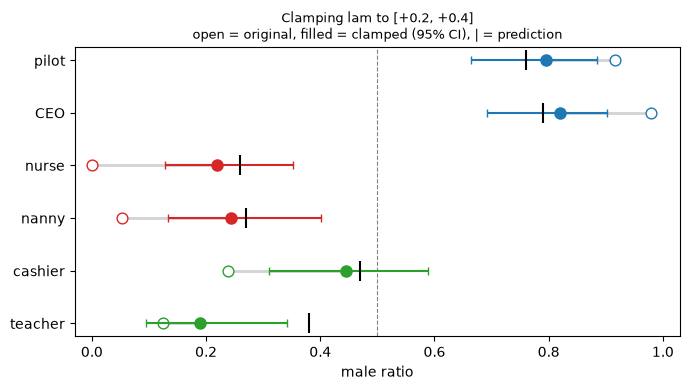

In [4]:
colors = {**{j: "#1f77b4" for j in GEN_JOBS["male"]}, **{j: "#d62728" for j in GEN_JOBS["female"]},
          **{j: "#2ca02c" for j in GEN_JOBS["neutral"]}}
y = np.arange(len(JOB_ORDER))[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
for yi, j in zip(y, JOB_ORDER):
    ax.plot([res.original[j], res.actual[j]], [yi, yi], c="lightgray", lw=2, zorder=1)
    ax.scatter(res.original[j], yi, c="white", edgecolors=colors[j], s=60, zorder=2)
    ax.errorbar(res.actual[j], yi, xerr=[[res.actual[j] - res.ci_lo[j]], [res.ci_hi[j] - res.actual[j]]],
                fmt="o", c=colors[j], ms=8, capsize=3, zorder=3)
    ax.scatter(res.predicted[j], yi, marker="|", c="black", s=200, zorder=4)
ax.axvline(0.5, ls="--", c="gray", lw=0.8)
ax.set_yticks(y, JOB_ORDER); ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("male ratio")
ax.set_title(f"Clamping lam to [{0.3 - 0.1:+.1f}, {0.3 + 0.1:+.1f}]\n"
             "open = original, filled = clamped (95% CI), | = prediction", fontsize=9)
plt.tight_layout(); plt.savefig(FIG + "clamp_result.png", dpi=200, bbox_inches="tight"); plt.show()

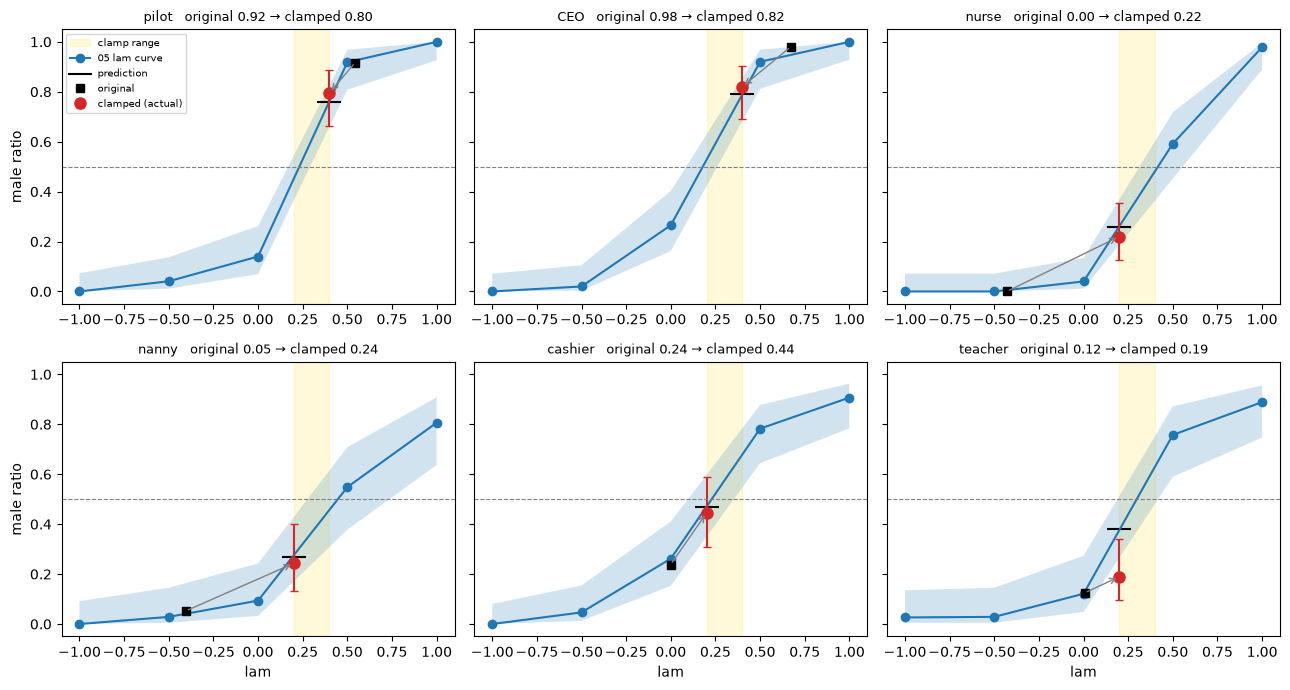

In [7]:
# 05의 lam 곡선 (judgments.csv) 위에 클리핑 결과를 겹쳐 그림
def curve(job):
    rows = []
    for t, l in zip(LAM_TAGS, LAMS):
        r = male_rate(J[J.cond == t]).loc[job]
        rows.append((l, r.rate, r.lo, r.hi))
    return np.array(rows)

p0 = J[J.cond == "original"].groupby("job").p_lam.first()
lo_b, hi_b = 0.3 - 0.1, 0.3 + 0.1

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, j in zip(axes.flat, JOB_ORDER):
    cv = curve(j)
    ax.axvspan(lo_b, hi_b, color="gold", alpha=0.15, label="clamp range")
    ax.fill_between(cv[:, 0], cv[:, 2], cv[:, 3], alpha=0.2)
    ax.plot(cv[:, 0], cv[:, 1], "o-", label="05 lam curve")
    ax.errorbar(p0[j], res.original[j], fmt="s", c="black", label="original")
    ax.annotate("", (res.target_lam[j], res.actual[j]), (p0[j], res.original[j]),
                arrowprops=dict(arrowstyle="->", color="gray", lw=1))
    ax.errorbar(res.target_lam[j], res.actual[j],
                yerr=[[res.actual[j] - res.ci_lo[j]], [res.ci_hi[j] - res.actual[j]]],
                fmt="o", c="tab:red", ms=8, capsize=3, label="clamped (actual)")
    ax.scatter(res.target_lam[j], res.predicted[j], marker="_", c="black", s=300,
               label="prediction")
    ax.axhline(0.5, ls="--", c="gray", lw=0.8)
    ax.set_title(f"{j}   original {res.original[j]:.2f} → clamped {res.actual[j]:.2f}", fontsize=9)
axes[0, 0].legend(fontsize=7, loc="upper left")
for ax in axes[1]: ax.set_xlabel("lam")
for ax in axes[:, 0]: ax.set_ylabel("male ratio")
plt.tight_layout(); plt.savefig(FIG + "clamp_on_curves.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. 같은 시드 비교: 원본 vs 클리핑

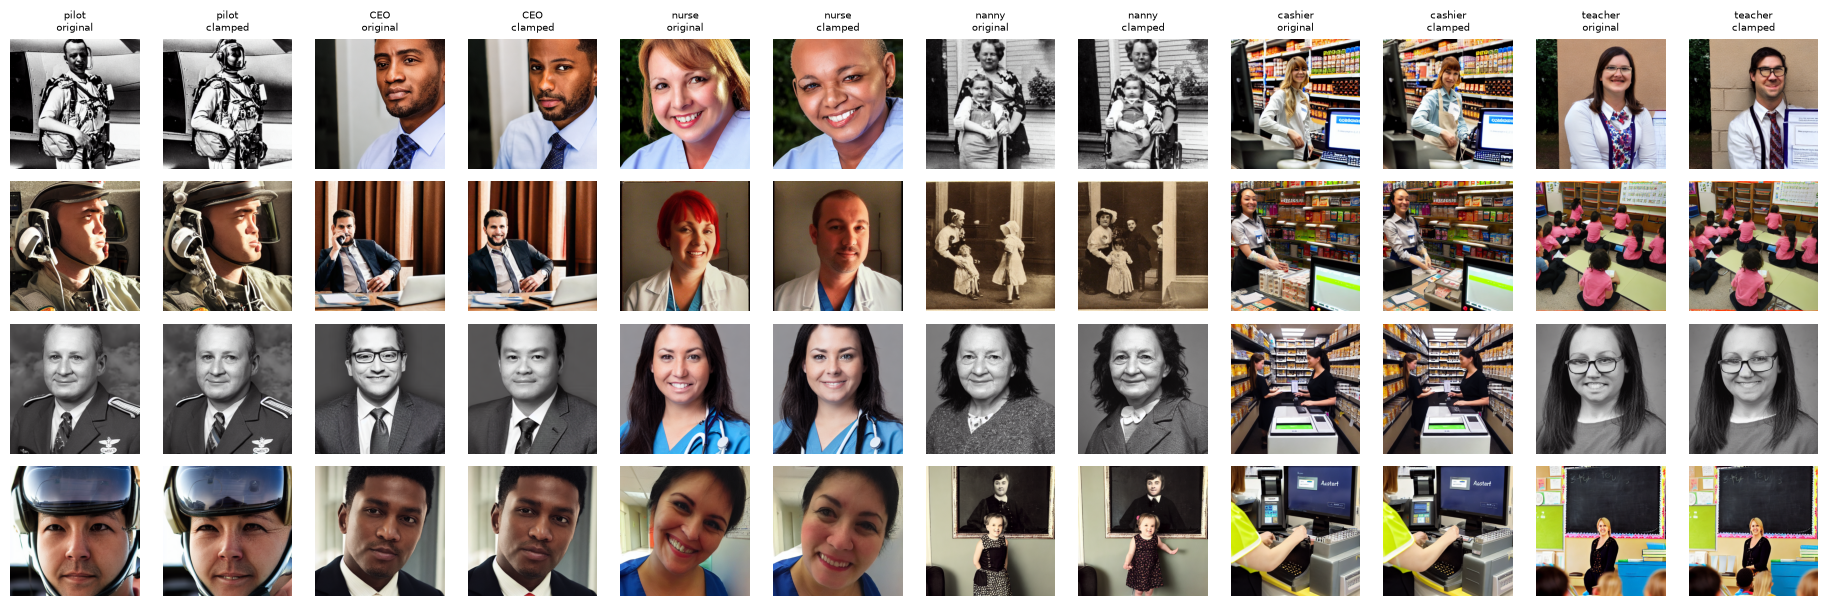

In [6]:
def clamp_grid(seeds=range(4)):
    fig, axes = plt.subplots(len(seeds), 2 * len(JOB_ORDER), figsize=(2 * 2 * len(JOB_ORDER) / 1.3, 2 * len(seeds) / 1.3))
    for i, sd in enumerate(seeds):
        for k, j in enumerate(JOB_ORDER):
            a, b = axes[i, 2 * k], axes[i, 2 * k + 1]
            a.imshow(Image.open(f"../outputs/images/{j}/{j}_original_s{sd:02d}.png"))
            b.imshow(Image.open(f"{IMG}{TAG}/{j}/{j}_{TAG}_s{sd:02d}.png"))
            a.axis("off"); b.axis("off")
            if i == 0:
                a.set_title(f"{j}\noriginal", fontsize=7); b.set_title(f"{j}\nclamped", fontsize=7)
    plt.tight_layout(); plt.savefig(FIG + "clamp_grid.png", dpi=150, bbox_inches="tight"); plt.show()

clamp_grid()

## 6. 부작용: CLIP score (원본 대비)

In [8]:
cs = pd.DataFrame({"original": J[J.cond == "original"].groupby("job").clip_score.mean(),
                   "clamped": C.groupby("job").clip_score.mean()}).loc[JOB_ORDER]
cs["diff"] = cs.clamped - cs.original
print(cs.round(1).to_string())

         original  clamped  diff
job                             
pilot        25.5     25.4  -0.1
CEO          18.8     18.7  -0.0
nurse        25.6     25.2  -0.4
nanny        23.3     22.9  -0.4
cashier      25.2     25.1  -0.0
teacher      21.9     21.9  -0.1
